# H3: does denoising improve cross-scanner reliability?

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import figs   # figs.py, next to this notebook

# Pipeline outputs (../pipeline/run_pipeline.sh): set RR_DERIV and RR_MANIFEST, or edit here
DERIV = Path(os.environ.get("RR_DERIV", "/path/to/derivatives"))
MANIFEST = Path(os.environ.get("RR_MANIFEST", "/path/to/ds004712_meta/sessions_manifest.csv"))
FIGS = DERIV / "analysis" / "figures" / "stage2"
EXPL = DERIV / "analysis" / "exploratory"
METRICS = ("FA", "MD", "MK")
pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams["figure.dpi"] = 60   # inline size; saved PNGs are 300 dpi

## Registered results

In [2]:
figs.results_table(DERIV, "H3")

,Hypothesis,ICC non-denoised,ICC denoised,ΔICC [95% CrI],P(ΔICC > 0),converged,verdict
0,H3a – FA voxel-wise,"0.017 [0.006, 0.045]","0.027 [0.010, 0.067]","+0.009 [-0.024, +0.052]",0.747,yes,inconclusive
1,H3a – MD voxel-wise,"0.034 [0.013, 0.084]","0.034 [0.013, 0.088]","+0.000 [-0.055, +0.059]",0.503,no,inconclusive
2,H3a – MK voxel-wise,"0.073 [0.029, 0.163]","0.126 [0.052, 0.278]","+0.052 [-0.064, +0.217]",0.809,no,inconclusive
3,H3b – FA ROI-wise,"0.097 [0.038, 0.224]","0.112 [0.044, 0.252]","+0.015 [-0.131, +0.179]",0.595,yes,inconclusive
4,H3b – MD ROI-wise,"0.090 [0.036, 0.204]","0.091 [0.036, 0.201]","+0.000 [-0.132, +0.132]",0.498,yes,inconclusive
5,H3b – MK ROI-wise,"0.129 [0.055, 0.268]","0.149 [0.062, 0.309]","+0.021 [-0.151, +0.206]",0.602,yes,inconclusive


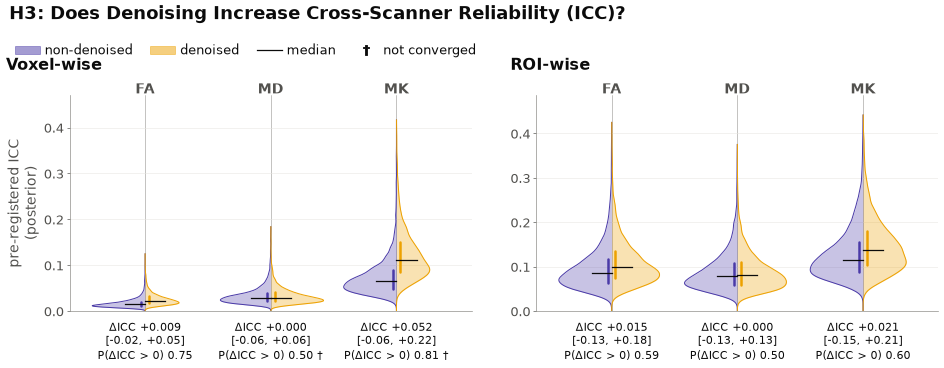

In [3]:
fig = figs.fig_h3(DERIV, METRICS, fs=16)
figs.save(fig, FIGS, "Fig4_H3")
plt.show()

## Exploratory results

In [4]:
import nibabel as nib  # noqa: E402

H3DIR = EXPL / "H3_unit_icc"
H3DIR.mkdir(parents=True, exist_ok=True)
ARMS = ("nondenoised", "denoised")
LEVELS = (("a", "voxel"), ("b", "ROI"))


def components(x):
    """x: (units, n subjects, k scanners) -> subject, scanner, residual variance per unit."""
    _, n, k = x.shape
    g = x.mean(axis=(1, 2), keepdims=True)
    rm, cm = x.mean(axis=2, keepdims=True), x.mean(axis=1, keepdims=True)
    msr = k * ((rm - g) ** 2).sum(axis=(1, 2)) / (n - 1)
    msc = n * ((cm - g) ** 2).sum(axis=(1, 2)) / (k - 1)
    mse = ((x - rm - cm + g) ** 2).sum(axis=(1, 2)) / ((n - 1) * (k - 1))
    return msr, msc, mse


def icc21(x):
    _, n, k = x.shape
    msr, msc, mse = components(x)
    icc = (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)
    vs, vc, ve = np.maximum((msr - mse) / k, 0), np.maximum((msc - mse) / n, 0), mse
    tot = vs + vc + ve
    return dict(icc=icc, share_subject=vs / tot, share_scanner=vc / tot, share_residual=ve / tot)


def table(lv, m):
    """(2 arms, units, n subjects, k scanners) array of the registered H3 inputs (repeats averaged) and unit ids."""
    t = pd.read_csv(DERIV / "analysis" / "inputs" / f"h3{lv}_{m}.csv.gz",
                    usecols=["subject", "scanner", "unit", "den", "y_raw"])
    units, subs, scs = (np.sort(t[c].unique()) for c in ("unit", "subject", "scanner"))
    y = np.full((2, units.size, subs.size, scs.size), np.nan)
    y[t["den"].to_numpy(), np.searchsorted(units, t["unit"]), np.searchsorted(subs, t["subject"]),
      np.searchsorted(scs, t["scanner"])] = t["y_raw"].to_numpy()
    assert not np.isnan(y).any(), "incomplete subject x scanner table"
    return y, units


mni2 = nib.load(str(figs.FSL_STD / "MNI152_T1_2mm_brain.nii.gz"))
atlas_img = nib.load(str(DERIV / "atlas" / "xtract_sub_1298.nii.gz"))
atlas = np.asarray(atlas_img.dataobj).astype(int)
unit_icc = {}
for lv, level in LEVELS:
    for m in METRICS:
        y, units = table(lv, m)
        r = {arm: icc21(y[d]) for d, arm in enumerate(ARMS)}
        df = pd.DataFrame({"unit": units, **{f"{k}_{arm}": v for arm in ARMS for k, v in r[arm].items()}})
        df["icc_diff"] = df.icc_denoised - df.icc_nondenoised
        unit_icc[level, m] = df
        df.to_csv(H3DIR / f"unit_icc_{lv}_{m}.csv.gz", index=False)
        ref = mni2 if lv == "a" else atlas_img
        for name, col in (("nondenoised", "icc_nondenoised"), ("denoised", "icc_denoised"), ("diff", "icc_diff")):
            if lv == "a":
                vol = np.full(ref.shape[:3], np.nan, np.float32)
                vol.flat[units] = df[col].to_numpy()
            else:
                lut = np.full(atlas.max() + 1, np.nan, np.float32)
                lut[units] = df[col].to_numpy()
                vol = lut[atlas]
            hdr = ref.header.copy(); hdr.set_data_dtype(np.float32); hdr.set_slope_inter(1, 0)
            tag, grid = ("vox", "MNI2mm") if lv == "a" else ("roi", "MNI1mm")
            nib.save(nib.Nifti1Image(vol, ref.affine, hdr), str(H3DIR / f"{tag}_{m}_{name}_{grid}.nii.gz"))

summary = pd.DataFrame([dict(level=lvl, metric=m, units=len(df), icc_non=df.icc_nondenoised.median(),
                             icc_den=df.icc_denoised.median(), median_dicc=df.icc_diff.median(), pct_units_higher=100 * (df.icc_diff > 0).mean(),
                             **{f"{s}_{a[:3]}": df[f"share_{s}_{a}"].median() for s in ("subject", "scanner", "residual")
                                for a in ARMS})
                        for (lvl, m), df in unit_icc.items()])
summary.round(3)

,level,metric,units,icc_non,icc_den,median_dicc,pct_units_higher,subject_non,subject_den,scanner_non,scanner_den,residual_non,residual_den
0,voxel,FA,9163,0.705,0.731,0.019,70.632,0.705,0.731,0.035,0.043,0.243,0.211
1,voxel,MD,9031,0.358,0.367,0.008,56.705,0.357,0.366,0.102,0.117,0.484,0.457
2,voxel,MK,2668,0.280,0.488,0.185,92.429,0.277,0.486,0.024,0.050,0.670,0.432
3,ROI,FA,1157,0.639,0.643,0.006,60.069,0.639,0.643,0.122,0.135,0.200,0.178
4,ROI,MD,1157,0.330,0.340,0.004,59.291,0.330,0.340,0.232,0.229,0.372,0.363
5,ROI,MK,1143,0.382,0.442,0.043,73.053,0.380,0.439,0.099,0.114,0.465,0.393


In [5]:
import warnings  # noqa: E402

MIN_SUBJECTS = 8                     # same rule as the H1 maps (pipeline/h1_maps.py --min-subjects)
WMDIR = H3DIR / "wm_maps"
WMDIR.mkdir(exist_ok=True)
man = pd.read_csv(MANIFEST)
scanner_of = {f"{r.subject}_{r.session}": r.scanner_label for r in man.itertuples()}
wm = np.asarray(nib.load(str(DERIV / "mmorf" / "MNI152_2mm_wm.nii.gz")).dataobj) > 0
sessions = sorted(p.name for p in (DERIV / "mmorf" / "nondenoised").glob("sub-*_ses-*"))
ses_sub = np.array([s.split("_")[0] for s in sessions])
ses_sc = np.array([scanner_of[s] for s in sessions])
subs, scs = np.unique(ses_sub), np.unique(ses_sc)


def icc21_rows(x):
    """ICC(2,1) per unit on the complete subject rows only. x: (units, n, k), a subject row is all-NaN if incomplete."""
    k = x.shape[2]
    ok = np.isfinite(x).all(axis=2)
    n = ok.sum(axis=1).astype(float)
    x = np.where(ok[..., None], x, np.nan)
    with warnings.catch_warnings(), np.errstate(invalid="ignore", divide="ignore"):
        warnings.simplefilter("ignore", RuntimeWarning)
        g = np.nanmean(x, axis=(1, 2), keepdims=True)
        rm, cm = np.nanmean(x, axis=2, keepdims=True), np.nanmean(x, axis=1, keepdims=True)
        msr = k * np.nansum((rm - g) ** 2, axis=(1, 2)) / (n - 1)
        msc = n * np.nansum((cm - g) ** 2, axis=(1, 2)) / (k - 1)
        mse = np.nansum((x - rm - cm + g) ** 2, axis=(1, 2)) / ((n - 1) * (k - 1))
        icc = (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)
    return icc, n


wm_cover = []
for m in METRICS:
    icc = {}
    for arm in ARMS:
        v = np.stack([np.asarray(nib.load(str(DERIV / "mmorf" / arm / s / f"{m}_MNI2mm_valid.nii.gz")).dataobj)[wm]
                      for s in sessions])
        x = np.full((v.shape[1], subs.size, scs.size), np.nan)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)                # all-NaN cells stay NaN
            for i, su in enumerate(subs):
                for j, sc in enumerate(scs):
                    sel = (ses_sub == su) & (ses_sc == sc)
                    x[:, i, j] = np.nanmean(v[sel], axis=0)            # repeats averaged over the valid ones
        icc[arm], nsub = icc21_rows(x)
    show = nsub >= MIN_SUBJECTS
    wm_cover.append(dict(metric=m, wm_voxels=int(wm.sum()), all_10_subjects=int((nsub == 10).sum()),
                         shown=int(show.sum()), shown_pct=100 * show.mean()))
    for name, val in (("nondenoised", icc["nondenoised"]), ("denoised", icc["denoised"]),
                      ("diff", icc["denoised"] - icc["nondenoised"]), ("nsub", nsub)):
        vol = np.full(wm.shape, np.nan, np.float32)
        vol[wm] = np.where(show, val, np.nan) if name != "nsub" else val
        hdr = mni2.header.copy(); hdr.set_data_dtype(np.float32); hdr.set_slope_inter(1, 0)
        nib.save(nib.Nifti1Image(vol, mni2.affine, hdr), str(WMDIR / f"vox_{m}_{name}_MNI2mm.nii.gz"))

# check: on the registered checkerboard voxels the display ICC equals the per-unit ICC above
for m in METRICS:
    d = np.asarray(nib.load(str(WMDIR / f"vox_{m}_diff_MNI2mm.nii.gz")).dataobj).ravel()
    ref = unit_icc["voxel", m]
    assert np.allclose(d[ref.unit.to_numpy()], ref.icc_diff.to_numpy(), atol=1e-5), m
pd.DataFrame(wm_cover).round(1)

,metric,wm_voxels,all_10_subjects,shown,shown_pct
0,FA,80532,73732,76768,95.3
1,MD,80532,72874,77360,96.1
2,MK,80532,24098,45685,56.7


In [6]:
def ratios(y):
    c0, c1 = components(y[0]), components(y[1])
    _, n, k = y[0].shape
    parts = lambda c: (np.maximum((c[0] - c[2]) / k, 0), np.maximum((c[1] - c[2]) / n, 0), c[2])  # noqa: E731
    return np.array([b.mean() / a.mean() for a, b in zip(parts(c0), parts(c1))])


rows = []
for lv, level in LEVELS:
    for m in METRICS:
        y, _ = table(lv, m)
        mu = (y[0].mean(axis=(1, 2), keepdims=True) + y[1].mean(axis=(1, 2), keepdims=True)) / 2
        y = 100 * y / mu
        for c, name in enumerate(("subject", "scanner", "residual")):
            rows.append(dict(level=level, metric=m, component=name, ratio=ratios(y)[c]))
abs_var = pd.DataFrame(rows)
abs_var.to_csv(H3DIR / "abs_variance.csv", index=False)
abs_var.pivot_table(index=["level", "metric"], columns="component", values="ratio").round(2)

component     residual  scanner  subject
level metric                            
ROI   FA          0.89     1.00     1.06
      MD          0.95     0.97     0.98
      MK          0.86     1.14     1.05
voxel FA          0.84     0.93     0.95
      MD          0.91     0.95     0.98
      MK          0.40     0.89     0.91

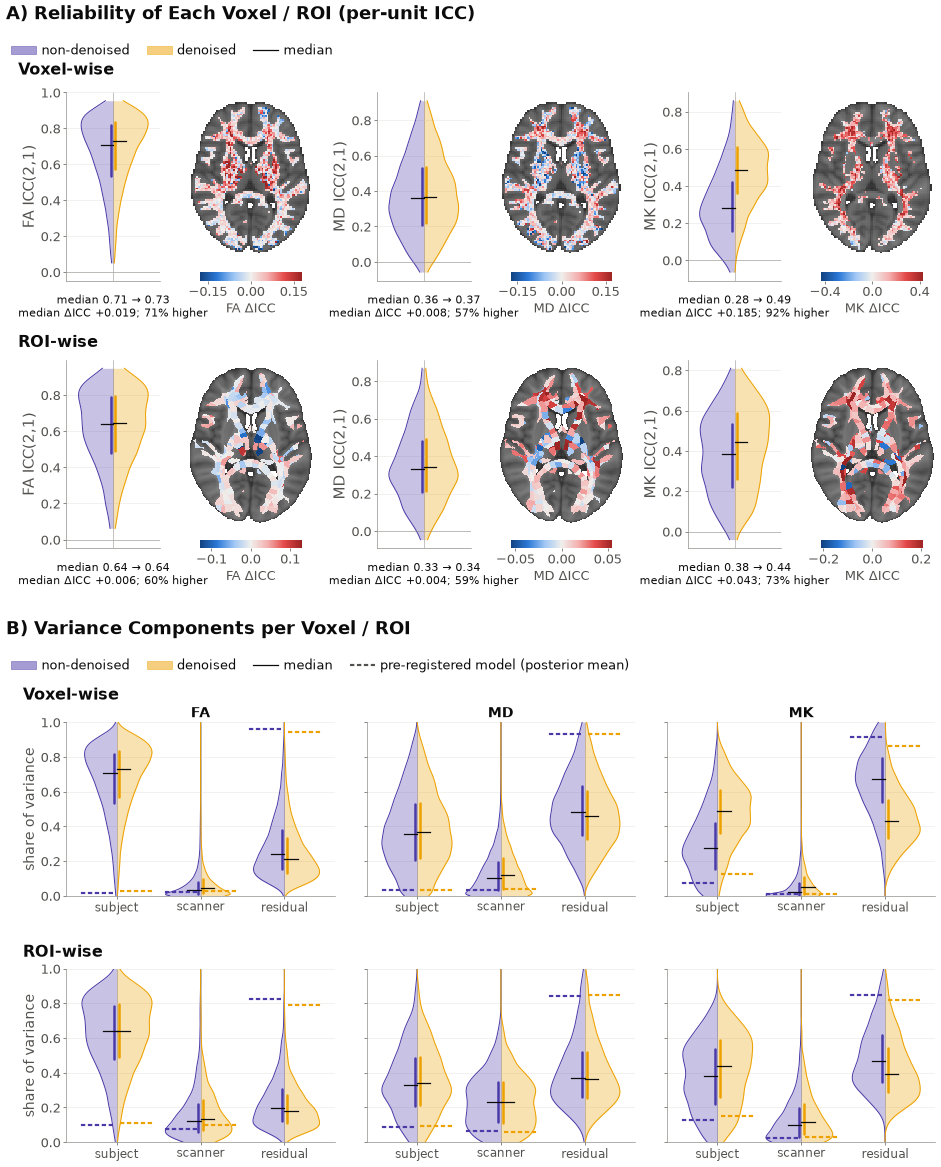

In [7]:
fig = figs.figx_h3(DERIV, METRICS, z=8, fs=16)
figs.save(fig, FIGS, "Fig8_H3_exploratory")
plt.show()